Using device: cuda
PyTorch version: 2.14.1+cu130


100%|██████████| 170M/170M [29:52<00:00, 95.1kB/s]



Dataset information:
Training samples: 45000
Validation samples: 5000
Test samples: 10000
Input image shape: torch.Size([3, 32, 32])
Flattened input size: 3072

PROBLEM 1.a - BASELINE MODEL
FullyConnectedNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
Trainable parameters: 1707274

PROBLEM 1.b - DEEPER MODEL
FullyConnectedNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=256, bias=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=256, bias=True)
    (8): ReLU()
    (9): Linear(in_features=256, out_feature

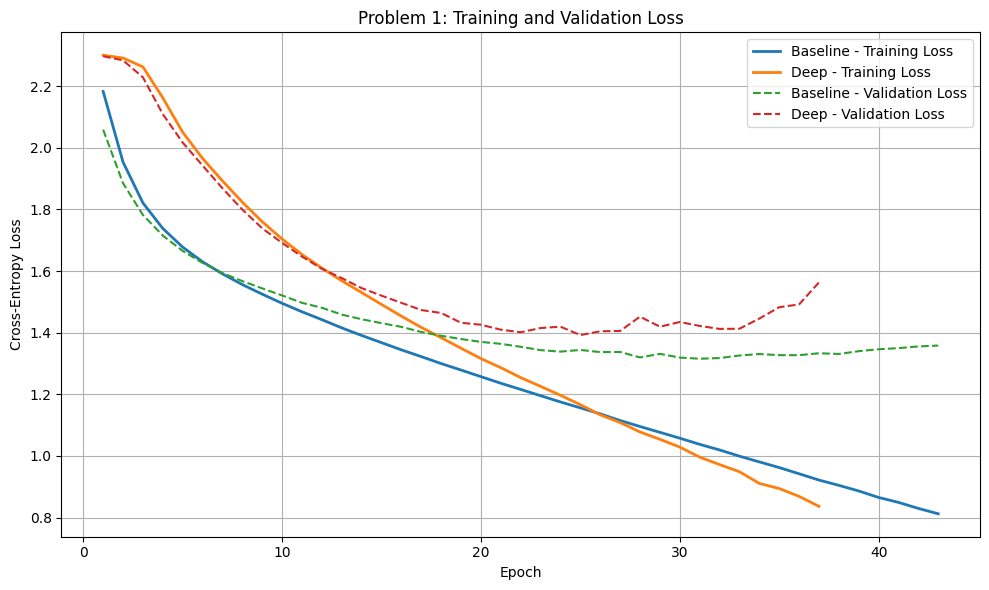

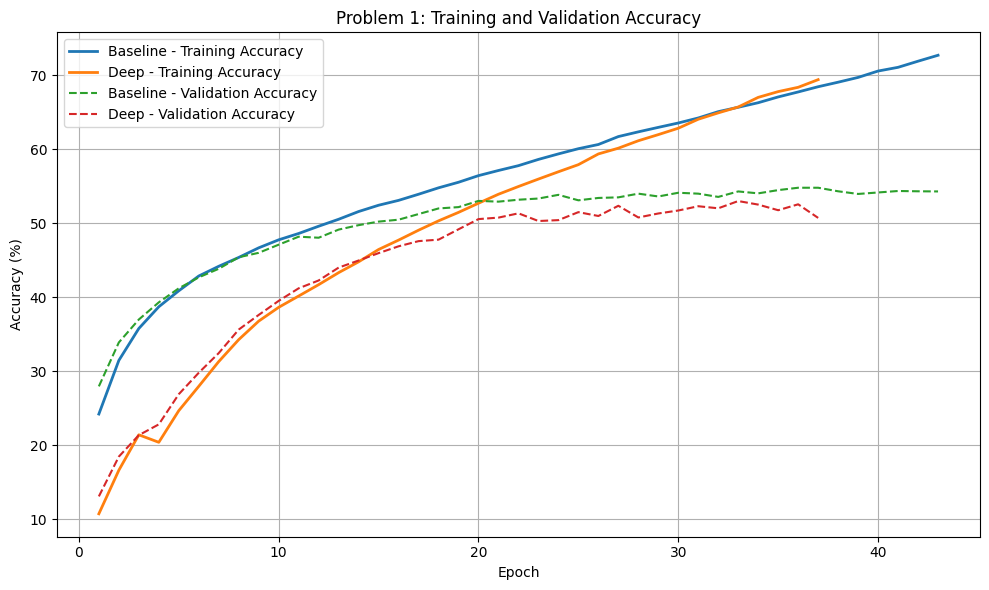

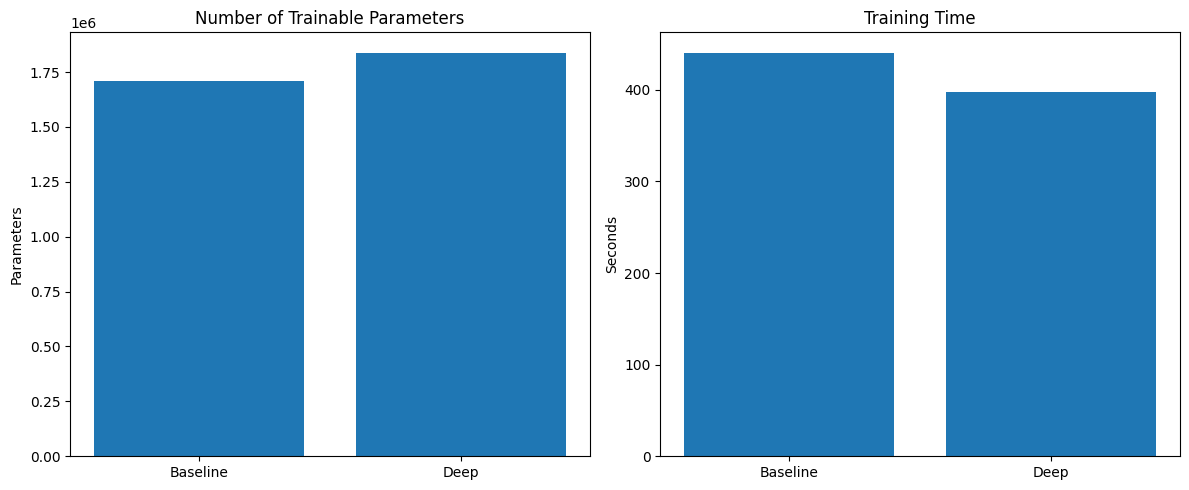


PROBLEM 1 ANALYSIS
Baseline test accuracy: 53.73%
Deep model test accuracy: 52.03%
Accuracy difference: -1.70 percentage points
Parameter difference: 131,584
Training time difference: -43.35 seconds
Baseline epochs: 43
Deep epochs: 37

Observation: The deeper model achieved lower test accuracy.
Problem 1a Baseline generalization gap: +12.15 percentage points
Problem 1b Deep generalization gap: +7.69 percentage points

All outputs saved in: HW7_Problem1_Results
Created ZIP: /content/HW7_Problem1_Results.zip

HOMEWORK 7 - PROBLEM 1 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 7 - PROBLEM 1 (PARTS 1.a AND 1.b)
# Fully Connected Neural Networks for CIFAR-10 Classification
#
# Name: Irtiza Hasan
# Student ID: 801419720
#
# Adapted from the programming approach in:
# https://github.com/HamedTabkhi/Intro-to-DL
#
# Colab: Runtime > Change runtime type > T4 GPU
# ============================================================

import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 100
PATIENCE = 12
LEARNING_RATE = 0.001
MOMENTUM = 0.9

OUTPUT_DIR = "HW7_Problem1_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)
print("PyTorch version:", torch.__version__)

# ============================================================
# 2. LOAD AND PREPROCESS CIFAR-10
# ============================================================

# Same normalization style as Dr. Tabkhi's LeNet.py
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Split the original 50,000 training images:
# 45,000 for gradient-based training
#  5,000 for validation / epoch selection
# Test set remains untouched during training.

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": 2,
    "pin_memory": device.type == "cuda"
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    **loader_kwargs
)

train_eval_loader = DataLoader(
    train_dataset,
    shuffle=False,
    **loader_kwargs
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_kwargs
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_kwargs
)

print("\nDataset information:")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Input image shape:", full_train_dataset[0][0].shape)
print("Flattened input size:", 3 * 32 * 32)

# ============================================================
# 3. DEFINE FULLY CONNECTED NEURAL NETWORK
# ============================================================

class FullyConnectedNN(nn.Module):

    def __init__(self, hidden_sizes):
        super().__init__()

        layers = [nn.Flatten()]
        input_size = 3 * 32 * 32

        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(input_size, hidden_size))
            layers.append(nn.ReLU())
            input_size = hidden_size

        # Output layer: 10 CIFAR-10 classes
        layers.append(nn.Linear(input_size, 10))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


# Problem 1.a: Two hidden layers
baseline_model = FullyConnectedNN(
    hidden_sizes=[512, 256]
)

# Problem 1.b: Four hidden layers
# Two additional 256-neuron hidden layers
deep_model = FullyConnectedNN(
    hidden_sizes=[512, 256, 256, 256]
)

def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("\n" + "=" * 60)
print("PROBLEM 1.a - BASELINE MODEL")
print("=" * 60)
print(baseline_model)
print("Trainable parameters:", count_parameters(baseline_model))

print("\n" + "=" * 60)
print("PROBLEM 1.b - DEEPER MODEL")
print("=" * 60)
print(deep_model)
print("Trainable parameters:", count_parameters(deep_model))

# ============================================================
# 4. EVALUATION FUNCTION
# ============================================================

criterion = nn.CrossEntropyLoss()

def evaluate(model, data_loader):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = running_loss / total
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy


# ============================================================
# 5. TRAINING FUNCTION
# ============================================================

def train_model(model, model_name):

    # Same optimization configuration for both models
    model = model.to(device)

    optimizer = optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    # Measure GPU training time correctly
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    print("\n" + "=" * 70)
    print("TRAINING:", model_name)
    print("=" * 70)

    for epoch in range(MAX_EPOCHS):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Clear previous gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)

            # Calculate cross-entropy loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            running_loss += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        # Training metrics for this epoch
        train_loss = running_loss / total
        train_accuracy = 100.0 * correct / total

        # Validation metrics for this epoch
        val_loss, val_accuracy = evaluate(
            model, val_loader
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch + 1:3d}/{MAX_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

        # Early stopping based on validation loss
        if val_loss < best_val_loss - 1e-4:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:

            print(
                f"\nEarly stopping at epoch {epoch + 1}."
            )
            print(
                f"Best validation epoch: {best_epoch}"
            )
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    # Restore model weights from best validation epoch
    model.load_state_dict(best_weights)

    # Final metrics using selected model
    final_train_loss, final_train_acc = evaluate(
        model, train_eval_loader
    )

    final_val_loss, final_val_acc = evaluate(
        model, val_loader
    )

    # Test data is evaluated only after model selection
    test_loss, test_accuracy = evaluate(
        model, test_loader
    )

    epochs_trained = len(history["train_loss"])

    results = {
        "Model": model_name,
        "Epochs Trained": epochs_trained,
        "Best Epoch": best_epoch,
        "Training Time (s)": round(training_time, 2),
        "Training Loss": round(final_train_loss, 4),
        "Training Accuracy (%)": round(final_train_acc, 2),
        "Validation Accuracy (%)": round(final_val_acc, 2),
        "Test Accuracy (%)": round(test_accuracy, 2),
        "Trainable Parameters": count_parameters(model)
    }

    print("\n" + "-" * 60)
    print("FINAL RESULTS:", model_name)
    print("-" * 60)

    for key, value in results.items():
        print(f"{key}: {value}")

    print(f"Test Loss: {test_loss:.4f}")

    # Save selected model
    filename = model_name.replace(" ", "_").replace(".", "")

    torch.save(
        model.state_dict(),
        os.path.join(
            OUTPUT_DIR,
            f"{filename}.pth"
        )
    )

    # Save per-epoch training history
    pd.DataFrame(history).to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{filename}_history.csv"
        ),
        index=False
    )

    return model, history, results


# ============================================================
# 6. PROBLEM 1.a - TRAIN BASELINE MLP
# ============================================================

baseline_model, baseline_history, baseline_results = train_model(
    baseline_model,
    "Problem 1a Baseline"
)

# ============================================================
# 7. PROBLEM 1.b - TRAIN DEEPER MLP
# ============================================================

deep_model, deep_history, deep_results = train_model(
    deep_model,
    "Problem 1b Deep"
)

# ============================================================
# 8. COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame([
    baseline_results,
    deep_results
])

print("\n" + "=" * 80)
print("HOMEWORK 7 - PROBLEM 1 COMPARISON")
print("=" * 80)

print(results_df.to_string(index=False))

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Problem1_Comparison.csv"
    ),
    index=False
)

# ============================================================
# 9. TRAINING LOSS CURVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(baseline_history["train_loss"]) + 1),
    baseline_history["train_loss"],
    label="Baseline - Training Loss",
    linewidth=2
)

plt.plot(
    range(1, len(deep_history["train_loss"]) + 1),
    deep_history["train_loss"],
    label="Deep - Training Loss",
    linewidth=2
)

plt.plot(
    range(1, len(baseline_history["val_loss"]) + 1),
    baseline_history["val_loss"],
    label="Baseline - Validation Loss",
    linestyle="--"
)

plt.plot(
    range(1, len(deep_history["val_loss"]) + 1),
    deep_history["val_loss"],
    label="Deep - Validation Loss",
    linestyle="--"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Problem 1: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "Problem1_Loss.png"),
    dpi=300
)

plt.show()

# ============================================================
# 10. TRAINING ACCURACY CURVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(baseline_history["train_accuracy"]) + 1),
    baseline_history["train_accuracy"],
    label="Baseline - Training Accuracy",
    linewidth=2
)

plt.plot(
    range(1, len(deep_history["train_accuracy"]) + 1),
    deep_history["train_accuracy"],
    label="Deep - Training Accuracy",
    linewidth=2
)

plt.plot(
    range(1, len(baseline_history["val_accuracy"]) + 1),
    baseline_history["val_accuracy"],
    label="Baseline - Validation Accuracy",
    linestyle="--"
)

plt.plot(
    range(1, len(deep_history["val_accuracy"]) + 1),
    deep_history["val_accuracy"],
    label="Deep - Validation Accuracy",
    linestyle="--"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Problem 1: Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "Problem1_Accuracy.png"),
    dpi=300
)

plt.show()

# ============================================================
# 11. COMPARE MODEL SIZE AND TRAINING TIME
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

model_names = ["Baseline", "Deep"]

axes[0].bar(
    model_names,
    [
        baseline_results["Trainable Parameters"],
        deep_results["Trainable Parameters"]
    ]
)

axes[0].set_title("Number of Trainable Parameters")
axes[0].set_ylabel("Parameters")

axes[1].bar(
    model_names,
    [
        baseline_results["Training Time (s)"],
        deep_results["Training Time (s)"]
    ]
)

axes[1].set_title("Training Time")
axes[1].set_ylabel("Seconds")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Problem1_Model_Comparison.png"
    ),
    dpi=300
)

plt.show()

# ============================================================
# 12. AUTOMATED COMPARISON
# ============================================================

baseline_acc = baseline_results["Test Accuracy (%)"]
deep_acc = deep_results["Test Accuracy (%)"]

accuracy_difference = deep_acc - baseline_acc

baseline_time = baseline_results["Training Time (s)"]
deep_time = deep_results["Training Time (s)"]

baseline_params = baseline_results["Trainable Parameters"]
deep_params = deep_results["Trainable Parameters"]

print("\n" + "=" * 70)
print("PROBLEM 1 ANALYSIS")
print("=" * 70)

print(
    f"Baseline test accuracy: {baseline_acc:.2f}%"
)
print(
    f"Deep model test accuracy: {deep_acc:.2f}%"
)

print(
    f"Accuracy difference: {accuracy_difference:+.2f} percentage points"
)

print(
    f"Parameter difference: {deep_params - baseline_params:,}"
)

print(
    f"Training time difference: {deep_time - baseline_time:+.2f} seconds"
)

print(
    f"Baseline epochs: {baseline_results['Epochs Trained']}"
)
print(
    f"Deep epochs: {deep_results['Epochs Trained']}"
)

if accuracy_difference > 0:
    print(
        "\nObservation: The deeper model achieved higher test accuracy."
    )
elif accuracy_difference < 0:
    print(
        "\nObservation: The deeper model achieved lower test accuracy."
    )
else:
    print(
        "\nObservation: Both models achieved the same test accuracy."
    )

for result in [baseline_results, deep_results]:
    gap = (
        result["Training Accuracy (%)"]
        - result["Test Accuracy (%)"]
    )

    print(
        f"{result['Model']} generalization gap: "
        f"{gap:+.2f} percentage points"
    )

print("\nAll outputs saved in:", OUTPUT_DIR)

# ============================================================
# 13. DOWNLOAD RESULTS AS ZIP
# ============================================================

import shutil

zip_path = shutil.make_archive(
    OUTPUT_DIR,
    "zip",
    OUTPUT_DIR
)

print("Created ZIP:", zip_path)

# Uncomment to download automatically in Google Colab:
# from google.colab import files
# files.download(zip_path)

print("\nHOMEWORK 7 - PROBLEM 1 COMPLETE")


Device: cuda
Dataset already loaded.
Training samples: 45000
Validation samples: 5000
Test samples: 10000

PROBLEM 2.a - TEN HIDDEN LAYERS
FlexibleMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=256, bias=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=256, bias=True)
    (8): ReLU()
    (9): Linear(in_features=256, out_features=256, bias=True)
    (10): ReLU()
    (11): Linear(in_features=256, out_features=256, bias=True)
    (12): ReLU()
    (13): Linear(in_features=256, out_features=256, bias=True)
    (14): ReLU()
    (15): Linear(in_features=256, out_features=256, bias=True)
    (16): ReLU()
    (17): Linear(in_features=256, out_features=256, bias=True)
    (18): ReLU()
    (19): Linear(in_features=256, out_features=256, bias=True)
    (2

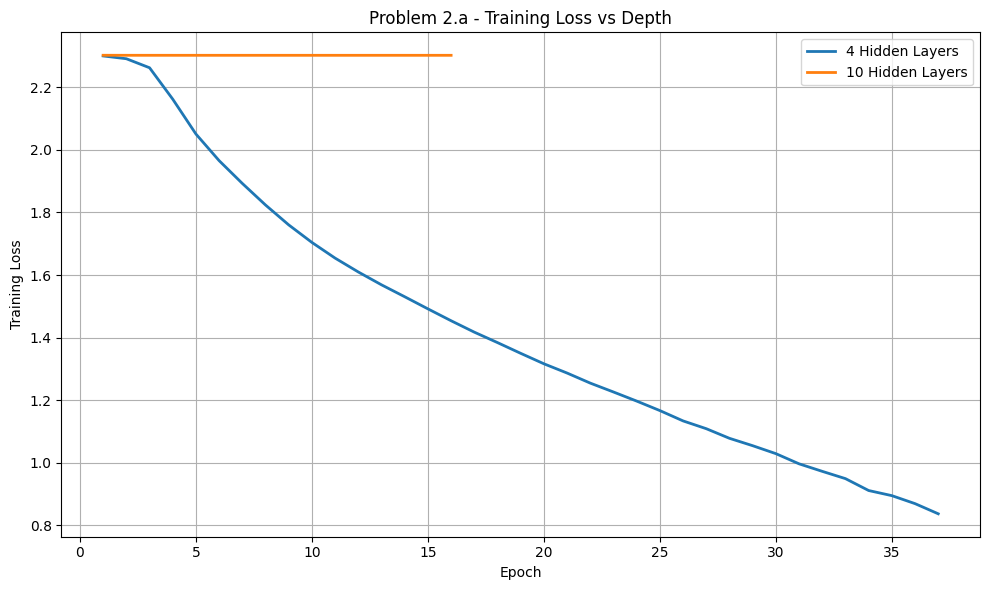

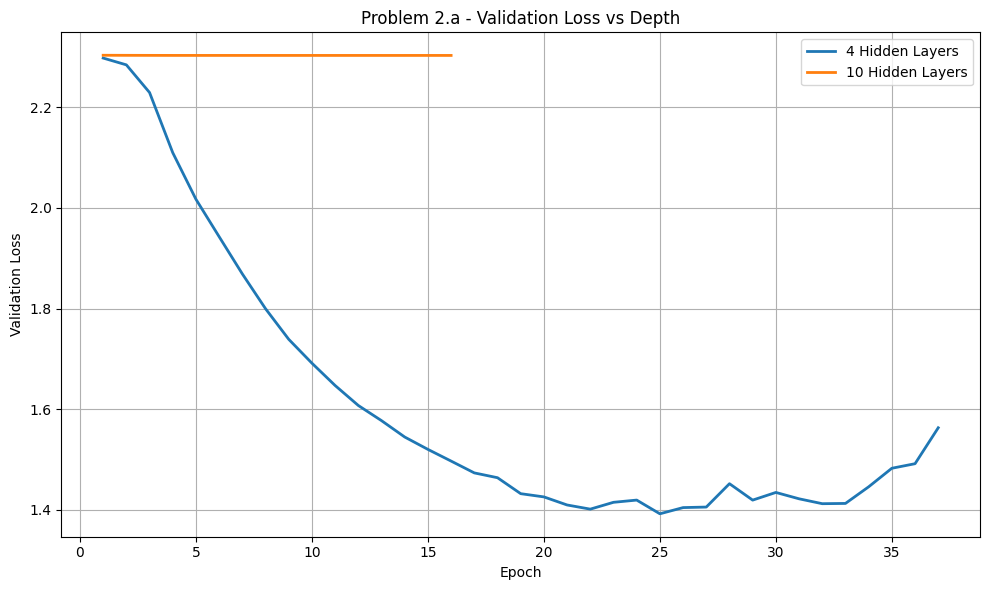

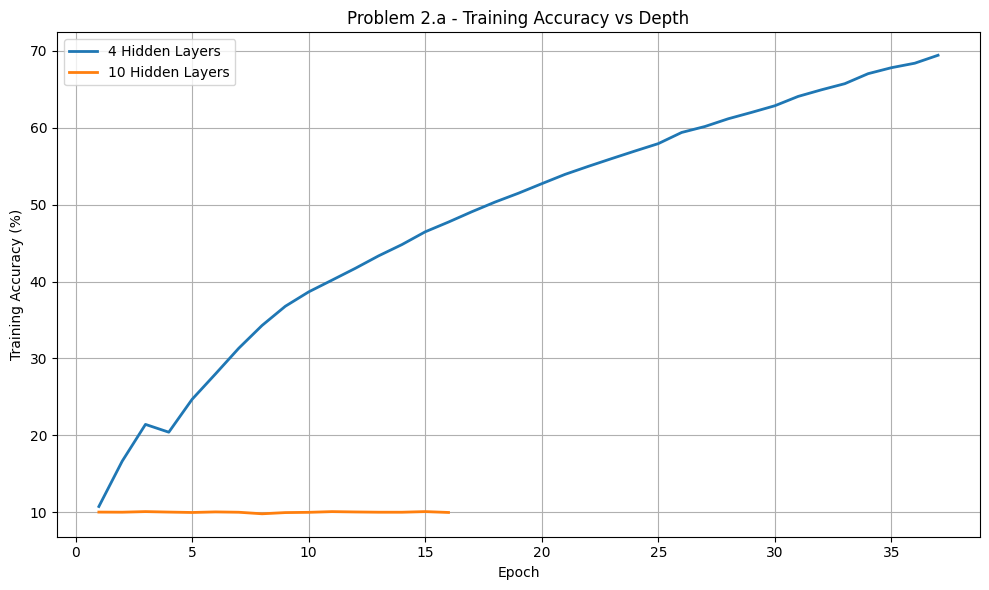

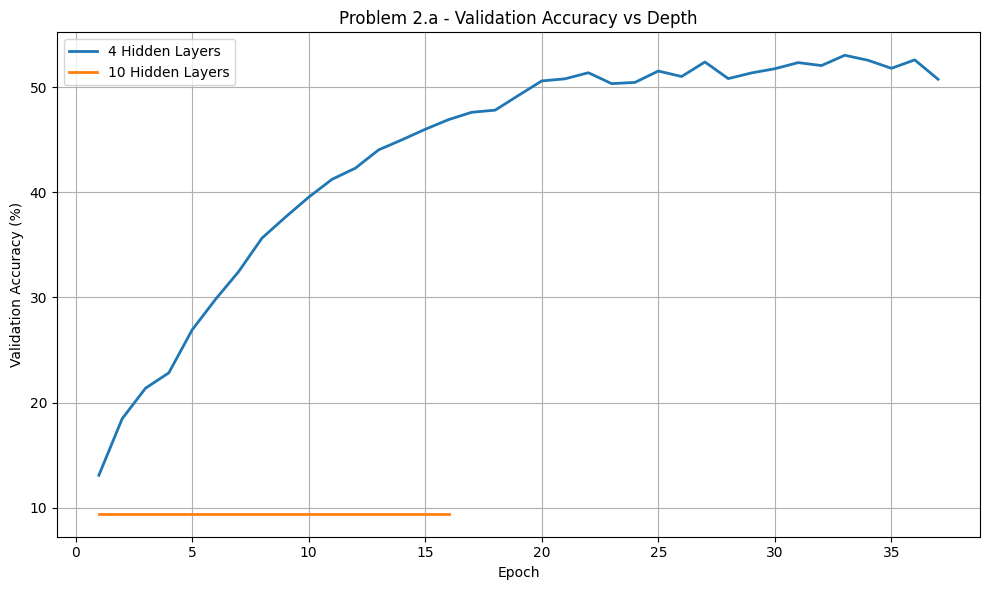

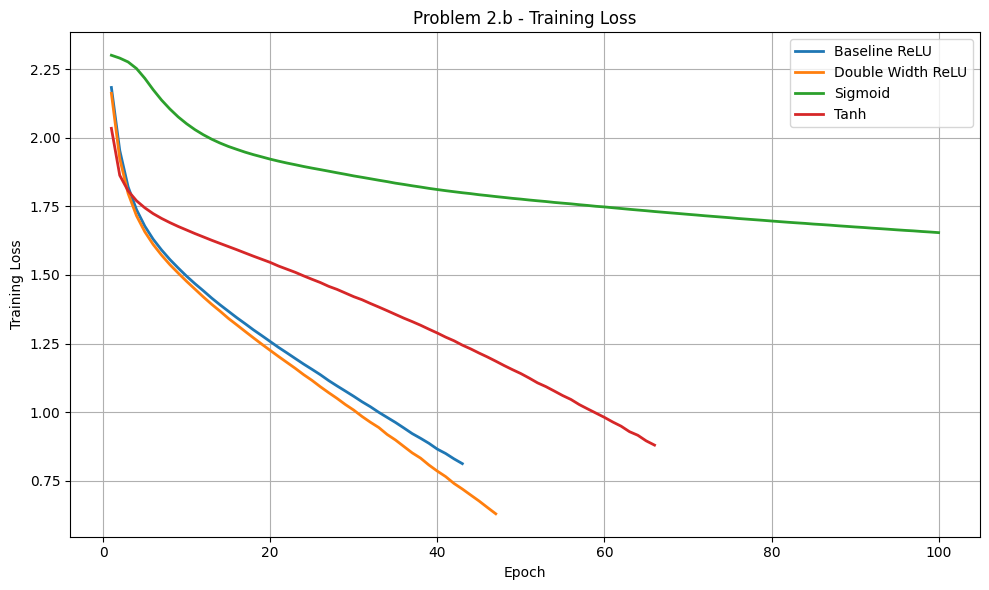

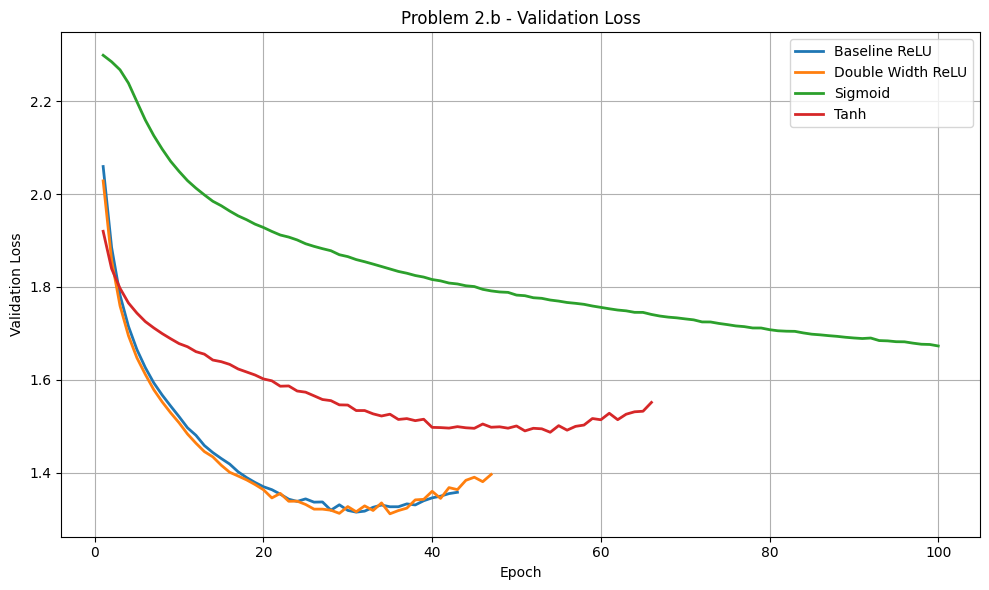

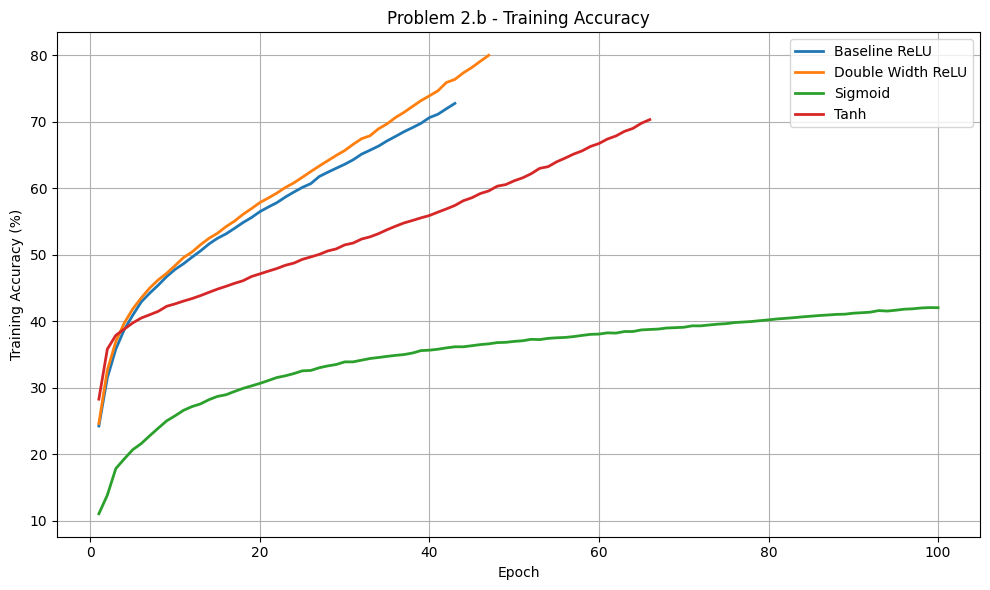

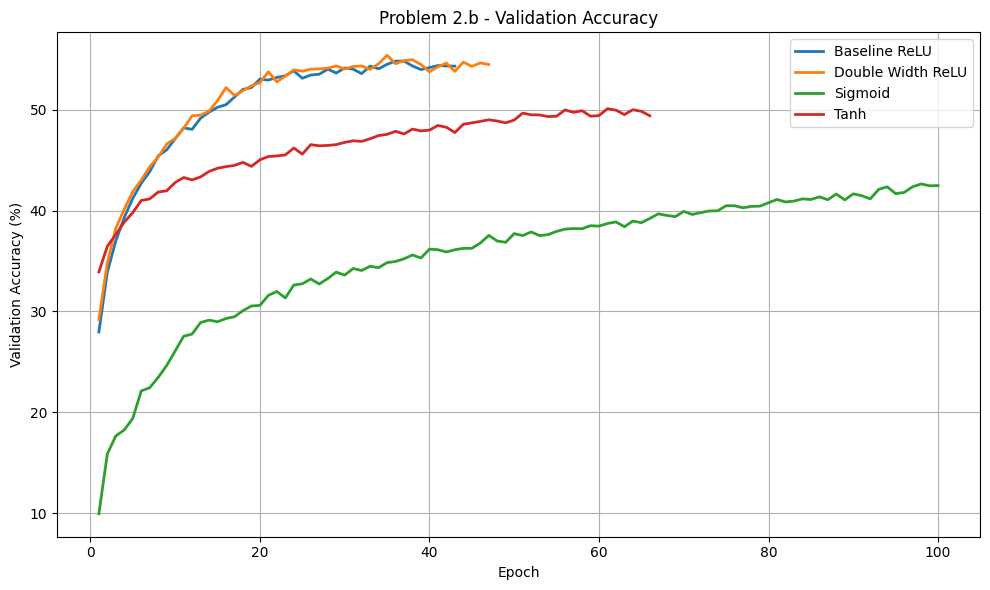

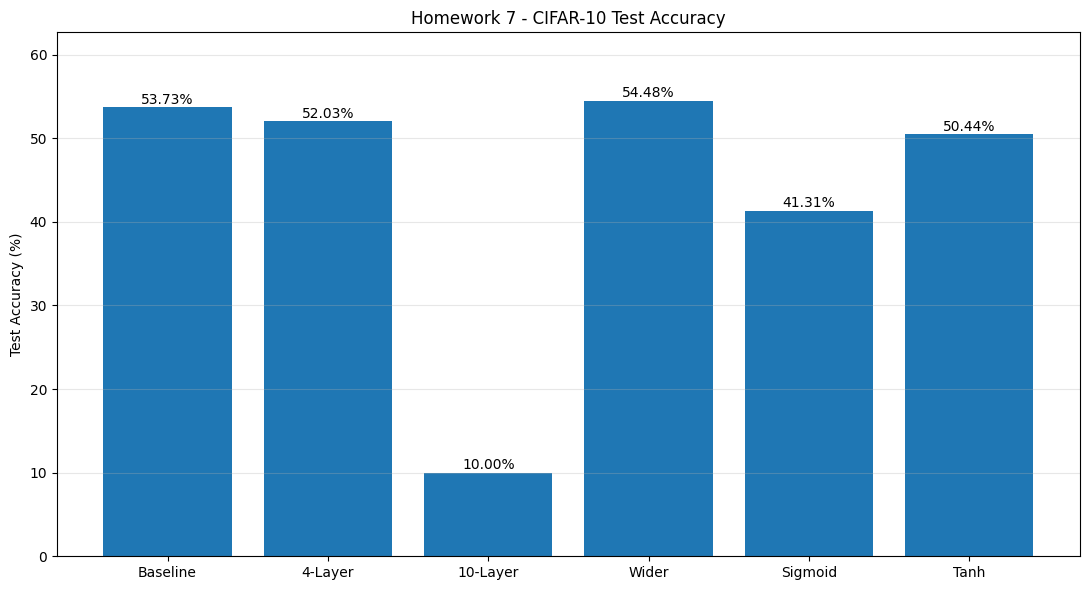

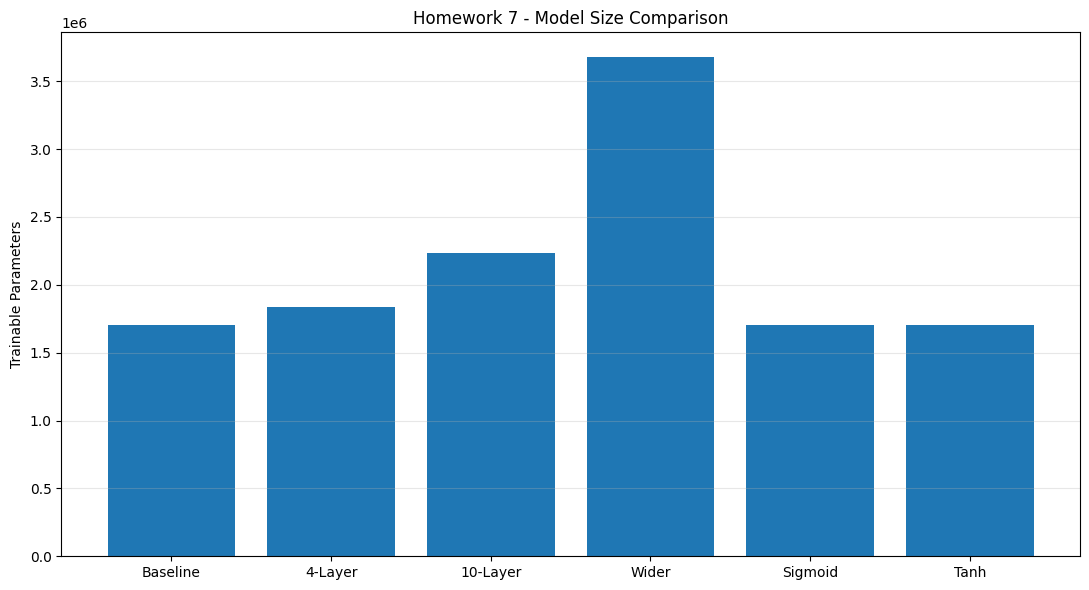

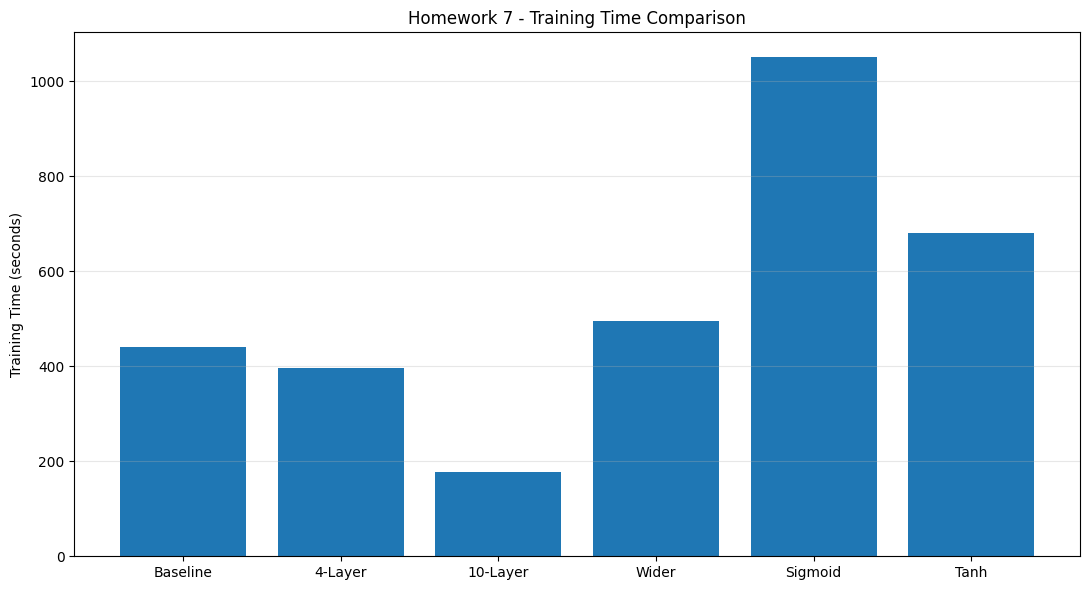


PROBLEM 2 - AUTOMATED ANALYSIS

PROBLEM 2.a: 10 Layers vs 4 Layers
Test accuracy change: -42.03 percentage points
Additional parameters: 394752

PROBLEM 2.b: Double Width vs Baseline
Test accuracy change: +0.75 percentage points
Additional parameters: 1969408

ACTIVATION COMPARISON:
Problem 1a Baseline: 53.73%
Problem 2b Sigmoid: 41.31%
Problem 2b Tanh: 50.44%

GENERALIZATION GAPS:
Problem 1a Baseline: +12.15 percentage points
Problem 1b Deep: +7.69 percentage points
Problem 2a Ten Layers: +0.06 percentage points
Problem 2b Wider ReLU: +17.08 percentage points
Problem 2b Sigmoid: +0.75 percentage points
Problem 2b Tanh: +14.69 percentage points

BEST OBSERVED TEST ACCURACY
Model: Problem 2b Wider ReLU
Test accuracy: 54.48
Trainable parameters: 3676682
Best epoch: 35

Saved all results to: /content/HW7_Problem1_Results.zip

HOMEWORK 7 - PROBLEMS 1 AND 2 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 7 - PROBLEM 2
# Impact of Network Depth, Width, and Activation Functions
#
# Name: Irtiza Hasan
# Student ID: 801419720
#
# Run AFTER completing Problem 1 in the same Colab runtime.
#
# Reuses:
# - CIFAR-10 dataset and DataLoaders
# - train_model() from Problem 1
# - baseline_results and deep_results
# - SGD, LR=0.001, momentum=0.9
# - Early stopping, max 100 epochs
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ============================================================
# 1. CHECK PROBLEM 1 VARIABLES
# ============================================================

required_variables = [
    "device",
    "train_loader",
    "train_eval_loader",
    "val_loader",
    "test_loader",
    "train_model",
    "baseline_results",
    "deep_results",
    "baseline_history",
    "deep_history",
    "OUTPUT_DIR"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Problem 1 first. Missing variables: "
        + ", ".join(missing)
    )

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Device:", device)
print("Dataset already loaded.")
print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Test samples:", len(test_loader.dataset))

# ============================================================
# 2. GENERAL FULLY CONNECTED NETWORK
# ============================================================

# Supports different depths, widths, and activations.
# Uses ONLY fully connected layers.
# No CNNs, convolution, or residual connections.

class FlexibleMLP(nn.Module):

    def __init__(self, hidden_sizes, activation="relu"):

        super().__init__()

        activations = {
            "relu": nn.ReLU,
            "sigmoid": nn.Sigmoid,
            "tanh": nn.Tanh
        }

        if activation not in activations:
            raise ValueError("Unsupported activation")

        activation_class = activations[activation]

        layers = [nn.Flatten()]

        input_size = 3 * 32 * 32

        for hidden_size in hidden_sizes:

            layers.append(
                nn.Linear(input_size, hidden_size)
            )

            layers.append(activation_class())

            input_size = hidden_size

        # Output logits for CrossEntropyLoss
        layers.append(nn.Linear(input_size, 10))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def parameter_count(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


def create_model(hidden_sizes, activation="relu"):

    # Reproducible initialization
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    return FlexibleMLP(
        hidden_sizes=hidden_sizes,
        activation=activation
    )


# ============================================================
# 3. PROBLEM 2.a - 10 HIDDEN LAYERS
# ============================================================

# Problem 1.b:
# 3072 -> 512 -> 256 -> 256 -> 256 -> 10
#
# Problem 2.a:
# 3072 -> 512 -> 256 -> 256 -> ... -> 256 -> 10
#
# 1 hidden layer with 512 neurons
# 9 hidden layers with 256 neurons
#
# Total: 10 hidden layers

hidden_sizes_2a = [512] + [256] * 9

assert len(hidden_sizes_2a) == 10

model_2a = create_model(
    hidden_sizes=hidden_sizes_2a,
    activation="relu"
)

print("\n" + "=" * 70)
print("PROBLEM 2.a - TEN HIDDEN LAYERS")
print("=" * 70)

print(model_2a)
print("Hidden layers:", len(hidden_sizes_2a))
print("Trainable parameters:", parameter_count(model_2a))

model_2a, history_2a, result_2a = train_model(
    model_2a,
    "Problem 2a Ten Layers"
)

# ============================================================
# 4. PROBLEM 2.b - EXPERIMENT 1: DOUBLE WIDTH
# ============================================================

# Original baseline: 512, 256
# Double width: 1024, 512
#
# Activation: ReLU
# Hidden layers: 2

model_width = create_model(
    hidden_sizes=[1024, 512],
    activation="relu"
)

print("\n" + "=" * 70)
print("PROBLEM 2.b - EXPERIMENT 1: DOUBLE WIDTH")
print("=" * 70)

print(model_width)
print("Trainable parameters:", parameter_count(model_width))

model_width, history_width, result_width = train_model(
    model_width,
    "Problem 2b Wider ReLU"
)

# ============================================================
# 5. PROBLEM 2.b - EXPERIMENT 2: SIGMOID
# ============================================================

# Same baseline architecture: 512, 256
# Replace ReLU with Sigmoid

model_sigmoid = create_model(
    hidden_sizes=[512, 256],
    activation="sigmoid"
)

print("\n" + "=" * 70)
print("PROBLEM 2.b - EXPERIMENT 2: SIGMOID")
print("=" * 70)

print(model_sigmoid)
print("Trainable parameters:", parameter_count(model_sigmoid))

model_sigmoid, history_sigmoid, result_sigmoid = train_model(
    model_sigmoid,
    "Problem 2b Sigmoid"
)

# ============================================================
# 6. PROBLEM 2.b - EXPERIMENT 3: TANH
# ============================================================

# Same baseline architecture: 512, 256
# Replace ReLU with Tanh

model_tanh = create_model(
    hidden_sizes=[512, 256],
    activation="tanh"
)

print("\n" + "=" * 70)
print("PROBLEM 2.b - EXPERIMENT 3: TANH")
print("=" * 70)

print(model_tanh)
print("Trainable parameters:", parameter_count(model_tanh))

model_tanh, history_tanh, result_tanh = train_model(
    model_tanh,
    "Problem 2b Tanh"
)

# ============================================================
# 7. PROBLEM 2.a COMPARISON TABLE
# ============================================================

comparison_2a = pd.DataFrame([
    deep_results,
    result_2a
])

print("\n" + "=" * 80)
print("PROBLEM 2.a - FOUR VS TEN HIDDEN LAYERS")
print("=" * 80)

print(comparison_2a.to_string(index=False))

comparison_2a.to_csv(
    os.path.join(OUTPUT_DIR, "Problem2a_Comparison.csv"),
    index=False
)

# ============================================================
# 8. PROBLEM 2.b COMPARISON TABLE
# ============================================================

comparison_2b = pd.DataFrame([
    baseline_results,
    result_width,
    result_sigmoid,
    result_tanh
])

print("\n" + "=" * 80)
print("PROBLEM 2.b - WIDTH AND ACTIVATIONS")
print("=" * 80)

print(comparison_2b.to_string(index=False))

comparison_2b.to_csv(
    os.path.join(OUTPUT_DIR, "Problem2b_Comparison.csv"),
    index=False
)

# ============================================================
# 9. ALL SIX MODELS COMPARISON
# ============================================================

all_results = pd.DataFrame([
    baseline_results,
    deep_results,
    result_2a,
    result_width,
    result_sigmoid,
    result_tanh
])

print("\n" + "=" * 90)
print("HOMEWORK 7 - ALL SIX NETWORKS")
print("=" * 90)

print(all_results.to_string(index=False))

all_results.to_csv(
    os.path.join(OUTPUT_DIR, "HW7_All_Results.csv"),
    index=False
)

# ============================================================
# 10. PLOTTING HELPER
# ============================================================

def plot_histories(
    history_dict,
    metric,
    ylabel,
    title,
    filename
):

    plt.figure(figsize=(10, 6))

    for name, history in history_dict.items():

        values = history[metric]
        epochs = range(1, len(values) + 1)

        plt.plot(
            epochs,
            values,
            linewidth=2,
            label=name
        )

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=300
    )

    plt.show()


# ============================================================
# 11. PROBLEM 2.a - LOSS AND ACCURACY CURVES
# ============================================================

depth_histories = {
    "4 Hidden Layers": deep_history,
    "10 Hidden Layers": history_2a
}

plot_histories(
    depth_histories,
    "train_loss",
    "Training Loss",
    "Problem 2.a - Training Loss vs Depth",
    "Problem2a_Train_Loss.png"
)

plot_histories(
    depth_histories,
    "val_loss",
    "Validation Loss",
    "Problem 2.a - Validation Loss vs Depth",
    "Problem2a_Val_Loss.png"
)

plot_histories(
    depth_histories,
    "train_accuracy",
    "Training Accuracy (%)",
    "Problem 2.a - Training Accuracy vs Depth",
    "Problem2a_Train_Accuracy.png"
)

plot_histories(
    depth_histories,
    "val_accuracy",
    "Validation Accuracy (%)",
    "Problem 2.a - Validation Accuracy vs Depth",
    "Problem2a_Val_Accuracy.png"
)

# ============================================================
# 12. PROBLEM 2.b - LOSS AND ACCURACY CURVES
# ============================================================

architecture_histories = {
    "Baseline ReLU": baseline_history,
    "Double Width ReLU": history_width,
    "Sigmoid": history_sigmoid,
    "Tanh": history_tanh
}

plot_histories(
    architecture_histories,
    "train_loss",
    "Training Loss",
    "Problem 2.b - Training Loss",
    "Problem2b_Train_Loss.png"
)

plot_histories(
    architecture_histories,
    "val_loss",
    "Validation Loss",
    "Problem 2.b - Validation Loss",
    "Problem2b_Val_Loss.png"
)

plot_histories(
    architecture_histories,
    "train_accuracy",
    "Training Accuracy (%)",
    "Problem 2.b - Training Accuracy",
    "Problem2b_Train_Accuracy.png"
)

plot_histories(
    architecture_histories,
    "val_accuracy",
    "Validation Accuracy (%)",
    "Problem 2.b - Validation Accuracy",
    "Problem2b_Val_Accuracy.png"
)

# ============================================================
# 13. ALL SIX MODELS - TEST ACCURACY
# ============================================================

short_names = [
    "Baseline",
    "4-Layer",
    "10-Layer",
    "Wider",
    "Sigmoid",
    "Tanh"
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    short_names,
    all_results["Test Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.title("Homework 7 - CIFAR-10 Test Accuracy")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f"{height:.2f}%",
        ha="center"
    )

plt.ylim(
    0,
    max(all_results["Test Accuracy (%)"]) * 1.15
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "HW7_Test_Accuracy.png"),
    dpi=300
)

plt.show()

# ============================================================
# 14. ALL SIX MODELS - PARAMETER COMPARISON
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    short_names,
    all_results["Trainable Parameters"]
)

plt.ylabel("Trainable Parameters")
plt.title("Homework 7 - Model Size Comparison")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "HW7_Parameters.png"),
    dpi=300
)

plt.show()

# ============================================================
# 15. ALL SIX MODELS - TRAINING TIME
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    short_names,
    all_results["Training Time (s)"]
)

plt.ylabel("Training Time (seconds)")
plt.title("Homework 7 - Training Time Comparison")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "HW7_Training_Time.png"),
    dpi=300
)

plt.show()

# ============================================================
# 16. AUTOMATED ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("PROBLEM 2 - AUTOMATED ANALYSIS")
print("=" * 80)

# 2.a: Depth comparison
depth_difference = (
    result_2a["Test Accuracy (%)"]
    - deep_results["Test Accuracy (%)"]
)

print("\nPROBLEM 2.a: 10 Layers vs 4 Layers")

print(
    "Test accuracy change:",
    f"{depth_difference:+.2f} percentage points"
)

print(
    "Additional parameters:",
    result_2a["Trainable Parameters"]
    - deep_results["Trainable Parameters"]
)

# 2.b: Width comparison
width_difference = (
    result_width["Test Accuracy (%)"]
    - baseline_results["Test Accuracy (%)"]
)

print("\nPROBLEM 2.b: Double Width vs Baseline")

print(
    "Test accuracy change:",
    f"{width_difference:+.2f} percentage points"
)

print(
    "Additional parameters:",
    result_width["Trainable Parameters"]
    - baseline_results["Trainable Parameters"]
)

# Activation comparison
print("\nACTIVATION COMPARISON:")

for result in [
    baseline_results,
    result_sigmoid,
    result_tanh
]:

    print(
        f"{result['Model']}: "
        f"{result['Test Accuracy (%)']:.2f}%"
    )

# Generalization gaps
print("\nGENERALIZATION GAPS:")

for result in all_results.to_dict("records"):

    gap = (
        result["Training Accuracy (%)"]
        - result["Test Accuracy (%)"]
    )

    print(
        f"{result['Model']}: "
        f"{gap:+.2f} percentage points"
    )

# Best test accuracy (descriptive comparison only)
best_index = all_results["Test Accuracy (%)"].idxmax()
best_model = all_results.loc[best_index]

print("\n" + "=" * 80)
print("BEST OBSERVED TEST ACCURACY")
print("=" * 80)

print("Model:", best_model["Model"])
print("Test accuracy:", best_model["Test Accuracy (%)"])
print("Trainable parameters:", best_model["Trainable Parameters"])
print("Best epoch:", best_model["Best Epoch"])

# ============================================================
# 17. SAVE ALL RESULTS AS ZIP
# ============================================================

import shutil

zip_path = shutil.make_archive(
    OUTPUT_DIR,
    "zip",
    OUTPUT_DIR
)

print("\nSaved all results to:", zip_path)

# Uncomment for automatic download from Colab
# from google.colab import files
# files.download(zip_path)

print("\nHOMEWORK 7 - PROBLEMS 1 AND 2 COMPLETE")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')